## 1. NER

In [ ]:
# Environment for week07: NLP tasks: NER, extractive QA, summarization.
# Colab or a fresh virtualenv: run this cell once. Locally: `uv sync --group week07` in the repo root instead.
%pip install -q "numpy>=1.26" "pandas>=2.2" "matplotlib>=3.9" "tqdm>=4.66" "torch>=2.4,<3" "transformers>=4.56,<5" "datasets>=3.6,<4" "evaluate>=0.4.3" "accelerate>=1.0" "seqeval>=1.2.2" "rouge-score>=0.1.2" "nltk>=3.9" "ipython>=8"


NER (Named Entity Recognition) is an information extraction task that identifies and classifies named entities, specific pieces of information in text, into predefined categories such as persons, organizations, locations, dates, products, etc.

### 1.1. Data
For this task we usually have a dataset in the CoNLL format:

For example,

`“Barack Obama was born in Honolulu and served as the 44th President of the United States.”`

| Token    | Label |
| -------- | ----- |
| Barack   | B-PER |
| Obama    | I-PER |
| Honolulu | B-LOC |
| United   | B-LOC |
| States   | I-LOC |

Where each label consists of basically one or two parts:

| Symbol                      | Meaning              |
| --------------------------- | -------------------- |
| `B-`                        | beginning of the entity      |
| `I-`                        | continuation of the entity |
| `O`                         | not an entity         |
| `PER`, `ORG`, `LOC`, `MISC` | types of the entities (person, organization, location, miscellaneous accordingly)       |

But let's take a look at the dataset itself (we'll download it from HuggingFace)

In [ ]:
from datasets import load_dataset

# conll2003 is a script-based dataset (now hosted as eriktks/conll2003): it needs datasets < 4 and trust_remote_code
dataset = load_dataset("eriktks/conll2003", trust_remote_code=True)
dataset

In [3]:
dataset['train'][0]

{'id': '0',
 'tokens': ['EU',
  'rejects',
  'German',
  'call',
  'to',
  'boycott',
  'British',
  'lamb',
  '.'],
 'pos_tags': [22, 42, 16, 21, 35, 37, 16, 21, 7],
 'chunk_tags': [11, 21, 11, 12, 21, 22, 11, 12, 0],
 'ner_tags': [3, 0, 7, 0, 0, 0, 7, 0, 0]}

Some of the datasets from `HuggingFace Hub` can have the method `features`. It can contain data types (`int8`, `float16`, `uint8`, `bool`, etc), label2idx mapping for categorical data, images and audios for CV and audio tasks respectfully.

For more information check [here]('https://huggingface.co/docs/datasets/v4.3.0/en/package_reference/main_classes#datasets.ClassLabel').

In [4]:
dataset['train'].features

{'id': Value(dtype='string', id=None),
 'tokens': Sequence(feature=Value(dtype='string', id=None), length=-1, id=None),
 'pos_tags': Sequence(feature=ClassLabel(names=['"', "''", '#', '$', '(', ')', ',', '.', ':', '``', 'CC', 'CD', 'DT', 'EX', 'FW', 'IN', 'JJ', 'JJR', 'JJS', 'LS', 'MD', 'NN', 'NNP', 'NNPS', 'NNS', 'NN|SYM', 'PDT', 'POS', 'PRP', 'PRP$', 'RB', 'RBR', 'RBS', 'RP', 'SYM', 'TO', 'UH', 'VB', 'VBD', 'VBG', 'VBN', 'VBP', 'VBZ', 'WDT', 'WP', 'WP$', 'WRB'], id=None), length=-1, id=None),
 'chunk_tags': Sequence(feature=ClassLabel(names=['O', 'B-ADJP', 'I-ADJP', 'B-ADVP', 'I-ADVP', 'B-CONJP', 'I-CONJP', 'B-INTJ', 'I-INTJ', 'B-LST', 'I-LST', 'B-NP', 'I-NP', 'B-PP', 'I-PP', 'B-PRT', 'I-PRT', 'B-SBAR', 'I-SBAR', 'B-UCP', 'I-UCP', 'B-VP', 'I-VP'], id=None), length=-1, id=None),
 'ner_tags': Sequence(feature=ClassLabel(names=['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC'], id=None), length=-1, id=None)}

In [5]:
dataset['train'].features['ner_tags']

Sequence(feature=ClassLabel(names=['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC'], id=None), length=-1, id=None)

In [6]:
dataset['train'].features['ner_tags'].feature.str2int('B-PER')

1

### 1.2. Tokenization

Now let's tokenize our sequences. The thing is, by now we have a sequence of _words_ matching the tags, but using BERT tokenizer, often word != token. That's why we need to create a function for their alignment.

In [7]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("bert-base-cased")

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/436k [00:00<?, ?B/s]

In [8]:
sequence = dataset['train'][23]['tokens']
tokenized_sequence = tokenizer.tokenize(sequence, truncation=True, is_split_into_words=True)
print(sequence)
print(tokenized_sequence)

['A', 'Florida', 'restaurant', 'paid', '10,925', 'pounds', '(', '$', '16,935', ')', 'for', 'the', 'draft', 'of', '"', 'Ai', "n't", 'no', 'telling', '"', ',', 'which', 'Hendrix', 'penned', 'on', 'a', 'piece', 'of', 'London', 'hotel', 'stationery', 'in', 'late', '1966', '.']
['A', 'Florida', 'restaurant', 'paid', '10', ',', '92', '##5', 'pounds', '(', '$', '16', ',', '93', '##5', ')', 'for', 'the', 'draft', 'of', '"', 'Ai', 'n', "'", 't', 'no', 'telling', '"', ',', 'which', 'Hendrix', 'penned', 'on', 'a', 'piece', 'of', 'London', 'hotel', 'station', '##ery', 'in', 'late', '1966', '.']


See? Told ya.

Although there is an easy way to see, which word was separated into a bunch of tokens, by using the method `.word_ids()` of the tokenizer:

In [9]:
print(tokenizer(sequence, truncation=True, is_split_into_words=True).word_ids())

[None, 0, 1, 2, 3, 4, 4, 4, 4, 5, 6, 7, 8, 8, 8, 8, 9, 10, 11, 12, 13, 14, 15, 16, 16, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 30, 31, 32, 33, 34, None]


`None` here means that the token isn't a word (`[CLS]`, `[SEP]`, etc tokens).

In [10]:
from typing import Dict, List, Any
from transformers import PreTrainedTokenizerBase

def tokenize_and_align_labels(
    examples: Dict[str, List[Any]],
    tokenizer: PreTrainedTokenizerBase,
    label_all_tokens: bool = True
) -> Dict[str, List[List[int]]]:

    tokenized_inputs = tokenizer(
        examples["tokens"],
        truncation=True,
        is_split_into_words=True,
    )

    labels = []
    for i, label in enumerate(examples["ner_tags"]):
        word_ids = tokenized_inputs.word_ids(batch_index=i)
        previous_word_idx = None
        label_ids = []

        for word_idx in word_ids:
            if word_idx is None:
                # skip the special token, we'll later show how
                label_ids.append(-100)
            elif word_idx != previous_word_idx:
                # beginning of the new word
                label_ids.append(label[word_idx])
            else:
                # continuation
                if label_all_tokens:
                    label_ids.append(label[word_idx])
                else:
                    label_ids.append(-100)
            previous_word_idx = word_idx

        labels.append(label_ids)

    tokenized_inputs["labels"] = labels

    # return dict for dataset mapping
    return tokenized_inputs


In [11]:
aligned_tokenized_dataset = dataset.map(
    lambda x: tokenize_and_align_labels(x, tokenizer),
    batched=True
)

Map:   0%|          | 0/14041 [00:00<?, ? examples/s]

Map:   0%|          | 0/3250 [00:00<?, ? examples/s]

Map:   0%|          | 0/3453 [00:00<?, ? examples/s]

### 1.3. Fine-tuning BERT to the task

So, the key idea here, that we're going to classify each token onto 9 classes (if each token is not an entity / the beginning of an entity / is the continuation of an entity):

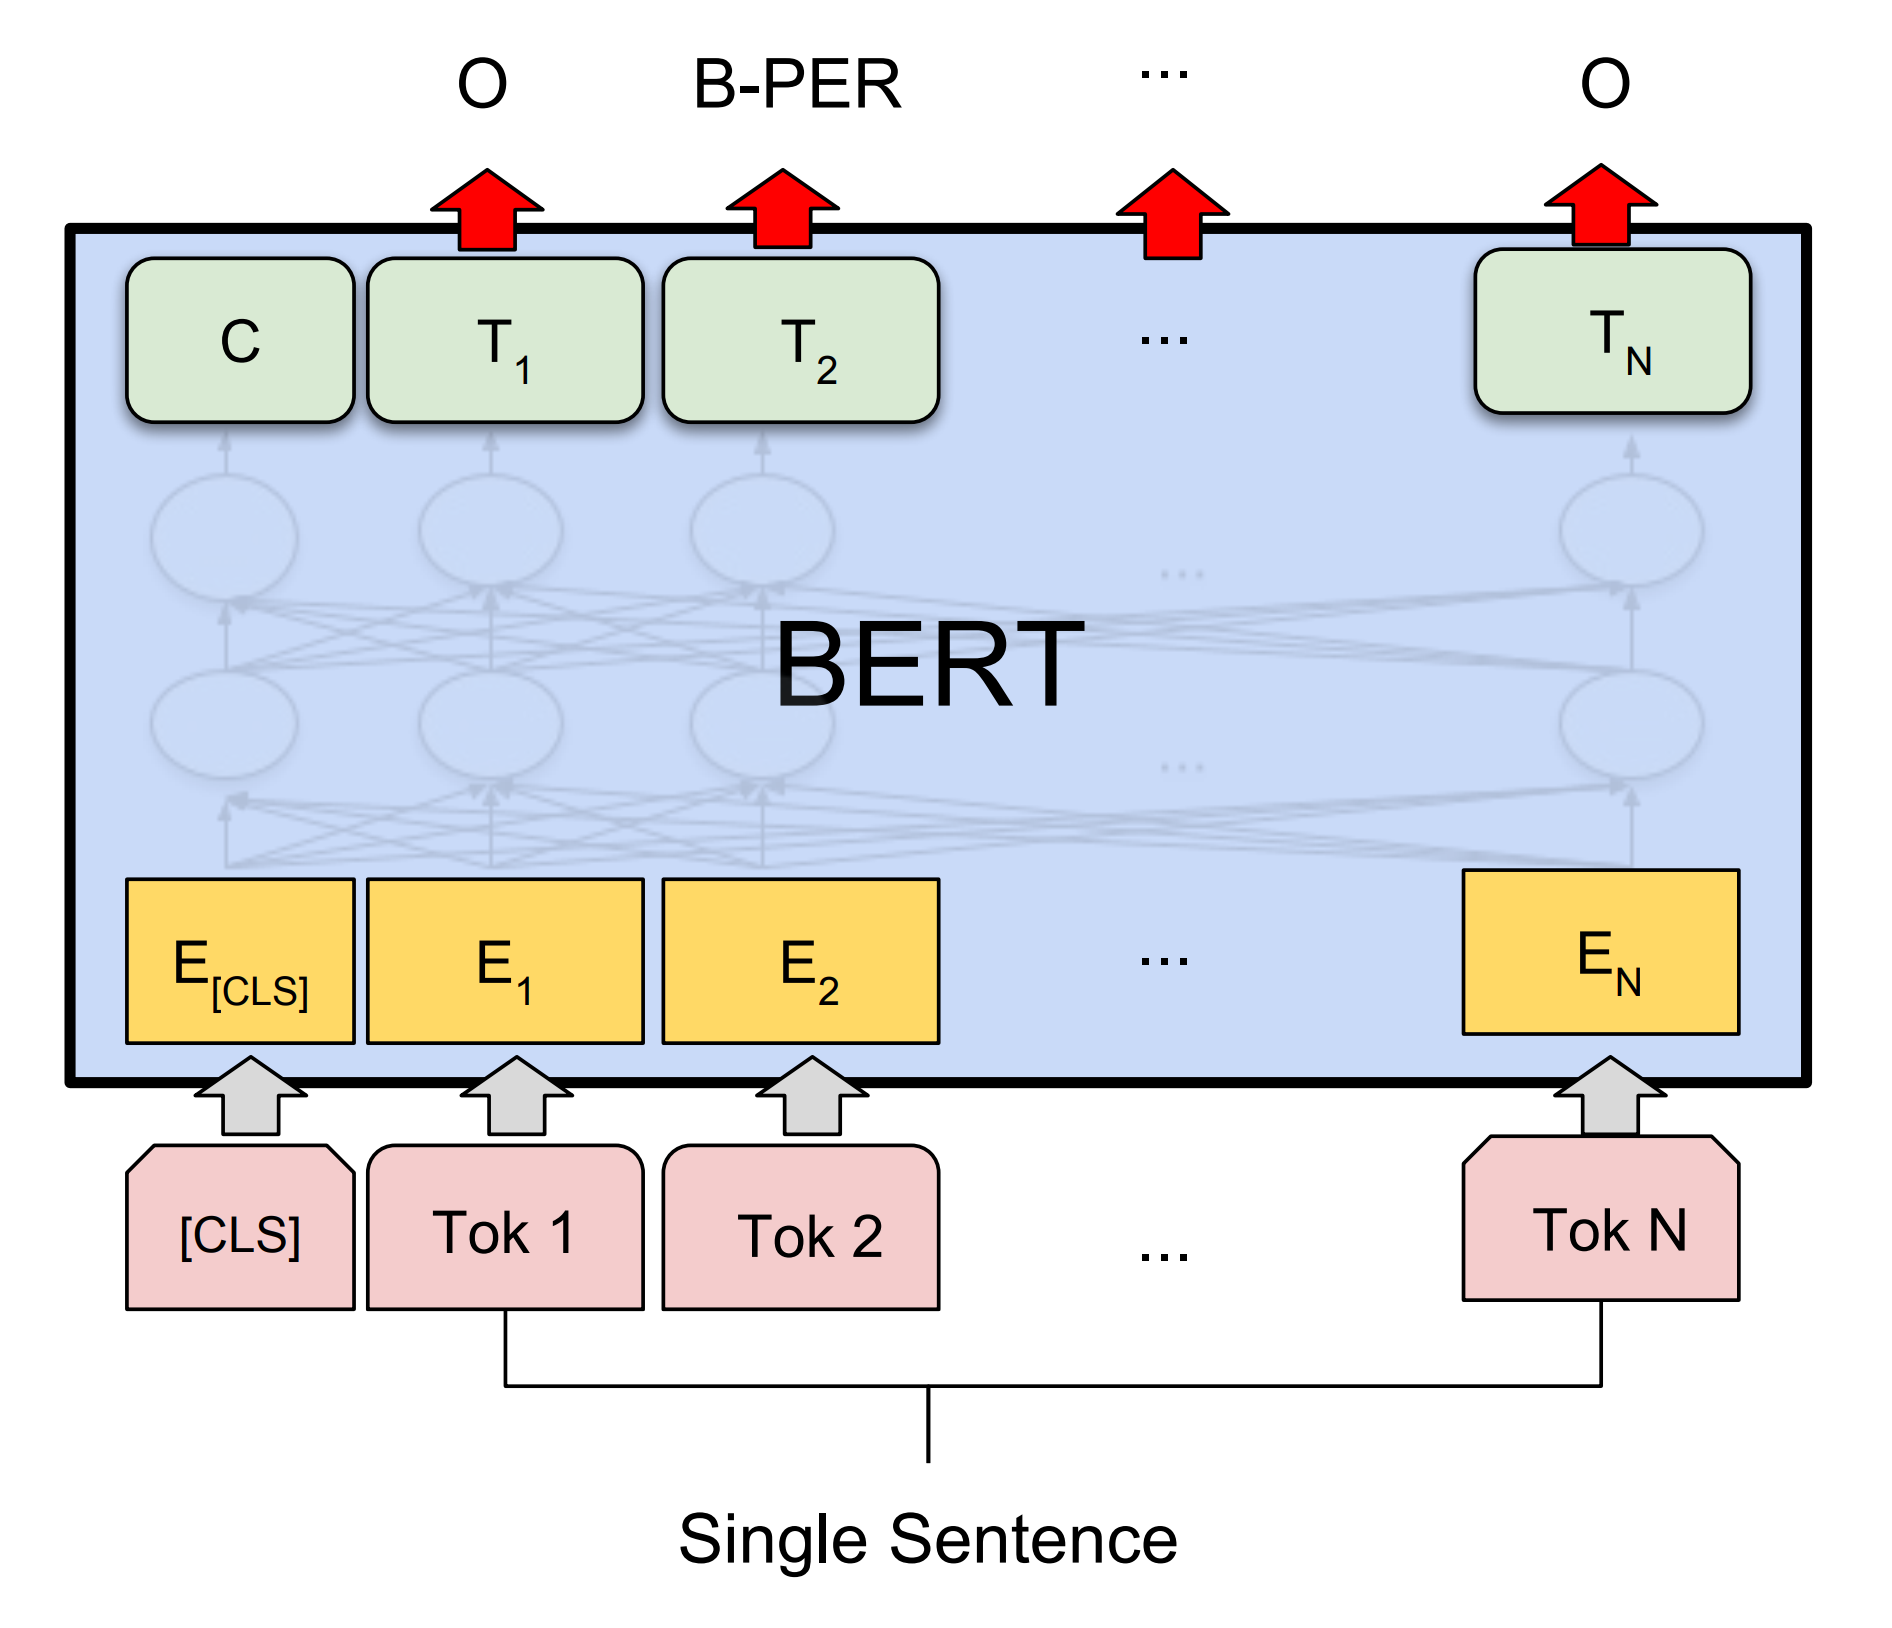

In [12]:
import torch
import torch.nn as nn
from transformers import AutoModel

In [13]:
BASE_MODEL = AutoModel.from_pretrained("bert-base-cased")

model.safetensors:   0%|          | 0.00/436M [00:00<?, ?B/s]

In [14]:
NUM_CLASSES = len(dataset['train'].features['ner_tags'].feature.names) # usually == 9
HIDDEN_SIZE = BASE_MODEL.config.hidden_size

In [15]:
class BERTforNER(nn.Module):
    def __init__(self, hidden_size: int = HIDDEN_SIZE, num_labels: int = NUM_CLASSES):
        super().__init__()
        self.bert = BASE_MODEL
        # freeze / turn off the model parameters
        for param in self.bert.parameters():
            param.requires_grad = False
        self.dropout = nn.Dropout(0.1)
        self.classifier = nn.Linear(hidden_size, num_labels)
        self.loss = nn.CrossEntropyLoss()

    def forward(self, input_ids, attention_mask=None, labels=None):
        outputs = self.bert(input_ids, attention_mask=attention_mask)
        sequence_output = outputs.last_hidden_state
        sequence_output = self.dropout(sequence_output)
        logits = self.classifier(sequence_output) # -> [batch_size, seq_len, num_labels]

        loss = None
        if labels is not None:
            # CrossEntropyLoss ignores values == -100 by default
            loss = self.loss(
                logits.view(-1, logits.shape[-1]), # input: -> [batch_size * seq_len, num_labels]
                labels.view(-1)                    # target: -> [batch_size * seq_len]
            )
        return {"loss": loss, "logits": logits}


In [16]:
model = BERTforNER()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
model.to(device)

Using device: cuda


BERTforNER(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(28996, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSdpaSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_af

In [17]:
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in model.parameters())

print(f"Trainable parameters: {trainable_params:,}")
print(f"Total parameters:     {total_params:,}")
print(f"Proportion trainable: {100 * trainable_params / total_params:.2f}%")

Trainable parameters: 6,921
Total parameters:     108,317,193
Proportion trainable: 0.01%


Let's also use `seqeval` metrics, that was designed for the evaluation of sequence labelling task performance.

In [ ]:
# take the label order from the dataset itself (B-ORG is 3 and B-LOC is 5 here; a hand-written mapping is easy to get wrong)
label_names = dataset['train'].features['ner_tags'].feature.names
id2label = dict(enumerate(label_names))
id2label

In [23]:
from evaluate import load
seqeval = load("seqeval")

def compute_metrics(p):
    predictions, labels = p
    predictions = predictions.argmax(-1)

    true_labels = []
    true_predictions = []

    for pred, lab in zip(predictions, labels):
        # deleting -100 paddings for special tokens
        valid_idx = lab != -100
        pred = pred[valid_idx]
        lab = lab[valid_idx]

        true_labels.append([id2label[l.item()] for l in lab])
        true_predictions.append([id2label[p.item()] for p in pred])

    results = seqeval.compute(predictions=true_predictions, references=true_labels)
    return {
        "precision": results["overall_precision"],
        "recall": results["overall_recall"],
        "f1": results["overall_f1"],
        "accuracy": results["overall_accuracy"],
    }


In [24]:
from transformers import Trainer, TrainingArguments, DataCollatorForTokenClassification

training_args = TrainingArguments(
    output_dir="./ner_model",
    eval_strategy="epoch",
    learning_rate=5e-3,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=16,
    num_train_epochs=2,
    weight_decay=0.01,
    logging_steps=200,
    save_strategy="epoch",
    report_to="none", # change to "wanbd" if you have one
)

data_collator = DataCollatorForTokenClassification(tokenizer=tokenizer)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=aligned_tokenized_dataset['train'],
    eval_dataset=aligned_tokenized_dataset['validation'],
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)
trainer.train()

Epoch,Training Loss,Validation Loss,Precision,Recall,F1,Accuracy
1,0.249900,0.220727,0.754587,0.726898,0.740483,0.940484
2,0.230800,0.201529,0.769782,0.761080,0.765406,0.945959


TrainOutput(global_step=878, training_loss=0.26224010354565597, metrics={'train_runtime': 125.5596, 'train_samples_per_second': 223.655, 'train_steps_per_second': 6.993, 'total_flos': 0.0, 'train_loss': 0.26224010354565597, 'epoch': 2.0})

Now let's check some examples to take a look how we're doing:

In [25]:
sample = aligned_tokenized_dataset['test'][0]
print("Tokens:", sample['tokens'])
print("NER Tags:", [id2label[token] for token in sample['ner_tags']])

Tokens: ['SOCCER', '-', 'JAPAN', 'GET', 'LUCKY', 'WIN', ',', 'CHINA', 'IN', 'SURPRISE', 'DEFEAT', '.']
NER Tags: ['O', 'O', 'B-ORG', 'O', 'O', 'O', 'O', 'B-PER', 'O', 'O', 'O', 'O']


In [26]:
model.eval()
with torch.no_grad():
    sample = aligned_tokenized_dataset['test'][0]
    inputs = {
        'input_ids': sample['input_ids'],
        'attention_mask': sample['attention_mask'],
        'labels': sample['labels']
    }
    inputs = data_collator([inputs])
    inputs = {k: v.to(device) for k, v in inputs.items()}
    outputs = model(**inputs)
    logits = outputs["logits"]
    predictions = torch.argmax(logits, dim=-1).squeeze().tolist()

print([id2label[token] for token in predictions])

['O', 'O', 'O', 'O', 'O', 'O', 'B-PER', 'B-PER', 'B-PER', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O']


Why would we even want to extract such entities?

**1. Financial news analysis**

When a company like *Apple Inc.* or *Goldman Sachs* appears in hundreds of news articles every day, analysts can’t manually read them all.
NER automatically detects mentions of organizations, people, and places, e.g., “Apple”, “Tim Cook”, “China”. This allows systems to track how often a company is mentioned, in what context (positive or negative), and to identify trends that may affect the market.

**2. Virtual assistants and chatbots**

When a user says, “Book a flight to Tokyo next Friday,” a chatbot must understand that “Tokyo” is a **location** and “next Friday” is a **date**.
NER helps extract these entities so the system can fill the right slots in a booking form.
Also, NER can be used for creating and maintaining so-called "Knowledge Graph" and relation extraction. By doing that we can either filter out the irrelevant data, or increase the retrieve relevancy.

**3. General usage**

Lots of businesses store millions of clients & employees data, containing personal information (names, addresses, dates of birth, e-mails, phone numbers). NER can automatically identify and mask this sensitive information (e.g., replacing “John Smith” with `[CLIENT_1]`) before the text is used for research, machine learning, or the other ways of processing. By doing this we can use external sevices, such as ChatGPT or other services for data processing that we are unable to perform by ourselves for some reason.

**Question:** what are the possible difficulties in the masking & de-masking task?

---

## 2. QA – Open Domain Question Answering

In extractive Question Answering (QA), the model is given:
 * a question
 * a context paragraph (where the answer appears)

and must find the *exact span* of text in the context that answers the question.
It doesn’t generate the answer, only extracts it.

### 2.1. Data

For this task we usually use a dataset in the **SQuAD** (Stanford Question Answering Dataset) format.

For example:

> **Context:**
> “Barack Obama was born in Honolulu and served as the 44th President of the United States.”

> **Question:**
> “Where was Barack Obama born?”

> **Answer:**
> “Honolulu”

Each example looks roughly like this:

```json
{
  "context": "Barack Obama was born in Honolulu and served as the 44th President of the United States.",
  "question": "Where was Barack Obama born?",
  "answers": {"text": ["Honolulu"], "answer_start": [25]}
}
```

We’ll use the SQuAD dataset from Hugging Face Datasets, which provides both the training and validation splits ready for tokenization and model training.


In [27]:
from datasets import load_dataset

squad = load_dataset("squad")

README.md: 0.00B [00:00, ?B/s]

plain_text/train-00000-of-00001.parquet:   0%|          | 0.00/14.5M [00:00<?, ?B/s]

plain_text/validation-00000-of-00001.par(…):   0%|          | 0.00/1.82M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/87599 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/10570 [00:00<?, ? examples/s]

In [28]:
squad['train'][0]

{'id': '5733be284776f41900661182',
 'title': 'University_of_Notre_Dame',
 'context': 'Architecturally, the school has a Catholic character. Atop the Main Building\'s gold dome is a golden statue of the Virgin Mary. Immediately in front of the Main Building and facing it, is a copper statue of Christ with arms upraised with the legend "Venite Ad Me Omnes". Next to the Main Building is the Basilica of the Sacred Heart. Immediately behind the basilica is the Grotto, a Marian place of prayer and reflection. It is a replica of the grotto at Lourdes, France where the Virgin Mary reputedly appeared to Saint Bernadette Soubirous in 1858. At the end of the main drive (and in a direct line that connects through 3 statues and the Gold Dome), is a simple, modern stone statue of Mary.',
 'question': 'To whom did the Virgin Mary allegedly appear in 1858 in Lourdes France?',
 'answers': {'text': ['Saint Bernadette Soubirous'], 'answer_start': [515]}}

Although, there is a thing, that we've been talking about the *span*, but seems like we have only `answer_start`... where is the `end`?

### 2.2. Tokenization & preprocessing

Now let's tokenize our sequences. To prepare our data we'll have to combine it into something like:

`[CLS] question [SEP] context [SEP] `

Firstly, we meet basically the same issue, that we faced with the NER task, tokenizing words onto tokens, but also there is more:

*What if the question + context combination is too long?*

We truncate only context and never truncate the question; we use a sliding window with overlapping chunks for context, so one combination of the question + answer can turn into a few.

In [29]:
"""
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("bert-base-cased")
"""

'\nfrom transformers import AutoTokenizer\n\ntokenizer = AutoTokenizer.from_pretrained("bert-base-cased")\n'

Let's take a look how it can be done:

In [30]:
question = squad['train'][42]['question']
context = squad['train'][42]['context']

In [31]:
tokenized_pair = tokenizer(
    text=question,
    text_pair=context,
    truncation="only_second",
    max_length=128,
    stride=32,
    return_overflowing_tokens=True
)
tokenized_pair

{'input_ids': [[101, 1327, 6556, 1104, 1651, 1120, 10360, 8022, 3360, 1107, 1103, 4503, 6605, 1788, 136, 102, 10360, 8022, 1110, 1227, 1111, 1157, 6591, 25831, 117, 1114, 1103, 16248, 1705, 4035, 10747, 1158, 1107, 2303, 1410, 19931, 124, 117, 4667, 1559, 1121, 170, 4528, 1104, 1407, 117, 17801, 113, 1627, 119, 128, 110, 114, 119, 1109, 3397, 6168, 1104, 1103, 7945, 1705, 3430, 1106, 2603, 1621, 1103, 1499, 1275, 1106, 1405, 1107, 1103, 3790, 1111, 1569, 1844, 5659, 119, 1109, 2755, 5660, 170, 1664, 118, 23951, 2109, 1346, 2168, 2818, 1115, 3643, 4120, 1651, 1106, 4615, 10296, 1106, 10360, 8022, 1112, 1218, 1112, 1251, 1168, 7632, 1106, 1134, 1152, 1127, 3134, 119, 122, 117, 3434, 1104, 1103, 124, 117, 4667, 1559, 113, 3614, 119, 122, 110, 114, 1127, 102], [101, 1327, 6556, 1104, 1651, 1120, 10360, 8022, 3360, 1107, 1103, 4503, 6605, 1788, 136, 102, 10296, 1106, 10360, 8022, 1112, 1218, 1112, 1251, 1168, 7632, 1106, 1134, 1152, 1127, 3134, 119, 122, 117, 3434, 1104, 1103, 124, 117, 466

Here we get 3 windows out of one pair:

In [32]:
print(len(tokenized_pair["input_ids"]))
print(tokenized_pair['input_ids'][0])

3
[101, 1327, 6556, 1104, 1651, 1120, 10360, 8022, 3360, 1107, 1103, 4503, 6605, 1788, 136, 102, 10360, 8022, 1110, 1227, 1111, 1157, 6591, 25831, 117, 1114, 1103, 16248, 1705, 4035, 10747, 1158, 1107, 2303, 1410, 19931, 124, 117, 4667, 1559, 1121, 170, 4528, 1104, 1407, 117, 17801, 113, 1627, 119, 128, 110, 114, 119, 1109, 3397, 6168, 1104, 1103, 7945, 1705, 3430, 1106, 2603, 1621, 1103, 1499, 1275, 1106, 1405, 1107, 1103, 3790, 1111, 1569, 1844, 5659, 119, 1109, 2755, 5660, 170, 1664, 118, 23951, 2109, 1346, 2168, 2818, 1115, 3643, 4120, 1651, 1106, 4615, 10296, 1106, 10360, 8022, 1112, 1218, 1112, 1251, 1168, 7632, 1106, 1134, 1152, 1127, 3134, 119, 122, 117, 3434, 1104, 1103, 124, 117, 4667, 1559, 113, 3614, 119, 122, 110, 114, 1127, 102]


And the `overflow_to_sample_mapping` shows that all of those windows are coming from the pair 0 (because we have just one pair in total...)

But if we got a batch of 5 pairs, and only the second one was too long, we'd receive something like
`[0, 1, 1, 1, 2, 3, 4]`
so we know that those 3 extras are coming from the pair two.

One more thing:

`return_offsets_mapping=True`

This option tells the tokenizer to return, for each token, the start and end character positions in the original text. It maps tokens -> character spans.

In [33]:
text = "Barack Obama was born in Hawaii."
tokens = tokenizer(text, return_offsets_mapping=True)
list(zip(tokens.tokens(), tokens["offset_mapping"]))

[('[CLS]', (0, 0)),
 ('Barack', (0, 6)),
 ('Obama', (7, 12)),
 ('was', (13, 16)),
 ('born', (17, 21)),
 ('in', (22, 24)),
 ('Hawaii', (25, 31)),
 ('.', (31, 32)),
 ('[SEP]', (0, 0))]

So you can see exactly which characters each token corresponds to.
This is crucial for SQuAD: it lets us match the character-level answer (answer_start, answer_end) to the correct token indices (start_positions, end_positions) used for training.

In [34]:
def preprocess_function(examples):
    questions = [q.strip() for q in examples["question"]]
    inputs = tokenizer(
        questions,
        examples["context"],
        truncation="only_second",
        max_length=384,
        stride=128,
        return_overflowing_tokens=True,
        return_offsets_mapping=True,
        padding="max_length"
    )

    # Extract useful metadata and remove it from the inputs
    # offset_mapping: character positions for each token in the original text
    # overflow_to_sample_mapping: tells which original example each window comes from
    offset_mapping = inputs.pop("offset_mapping")
    sample_map = inputs.pop("overflow_to_sample_mapping")
    start_positions = []
    end_positions = []

    # Go through each tokenized window
    for i, offsets in enumerate(offset_mapping):
        # Which original sample this window belongs to
        sample_idx = sample_map[i]
        # Get the answer text and its character positions
        answer = examples["answers"][sample_idx]
        start_char = answer["answer_start"][0]
        end_char = start_char + len(answer["text"][0])
        # sequence_ids marks which tokens belong to which part:
        # 0 = question, 1 = context, None = special tokens ([CLS], [SEP], padding)
        sequence_ids = inputs.sequence_ids(i)

        # Find where the context tokens start and end within this window
        idx = 0
        while sequence_ids[idx] != 1: idx += 1
        context_start = idx
        while idx < len(sequence_ids) and sequence_ids[idx] == 1: idx += 1
        context_end = idx - 1

        # If the answer is not fully inside this window, label it as [CLS] (no answer)
        if not (offsets[context_start][0] <= start_char and offsets[context_end][1] >= end_char):
            start_positions.append(0)
            end_positions.append(0)
        else:
            # Find the start token index: move right until token start > answer_start
            start_idx = context_start
            while start_idx <= context_end and offsets[start_idx][0] <= start_char:
                start_idx += 1
            start_positions.append(start_idx - 1)

            # Find the end token index: move left until token end < answer_end
            end_idx = context_end
            while end_idx >= context_start and offsets[end_idx][1] >= end_char:
                end_idx -= 1
            end_positions.append(end_idx + 1)

    inputs["start_positions"] = start_positions
    inputs["end_positions"] = end_positions
    return inputs


In [35]:
tokenized_squad = squad.map(preprocess_function, batched=True, remove_columns=squad["train"].column_names)

Map:   0%|          | 0/87599 [00:00<?, ? examples/s]

Map:   0%|          | 0/10570 [00:00<?, ? examples/s]

### 2.3. Fine-tuning BERT to the task

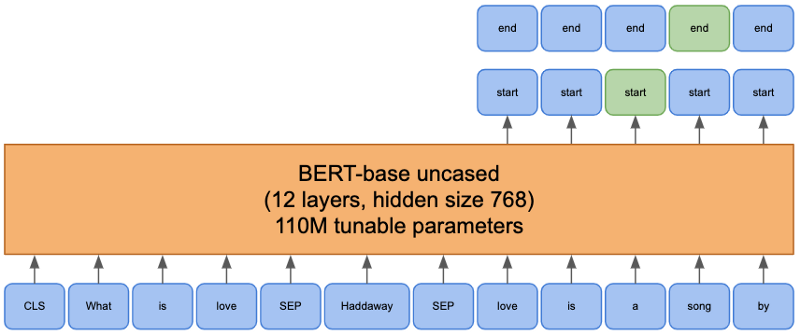

In extractive QA tasks, the model does not generate the answer, it learns to locate it within the context by predicting two positions:

* the start token of the answer
* the end token of the answer

You might think, that there is a token-wise classification onto 3 classes: start / end / none, but actually no. The task can be solved by having two classification heads: one returns the probability distribution between all the tokens as a starting, the other one returns the probability distribution between all the tokens as an ending ones.

Why it's incorrect to suppose that it's a token-wise classification? For example, by doing so we can get more than one answer-start and more than one answer-end.

In [36]:
import torch
import torch.nn as nn

class BERTforQA(nn.Module):
    def __init__(self, base_model, hidden_size: int = 768):
        super().__init__()
        self.bert = base_model

        # freeze all BERT parameters
        for p in self.bert.parameters():
            p.requires_grad = False

        self.qa_outputs = nn.Linear(hidden_size, 2)  # [start, end]
        self.loss = nn.CrossEntropyLoss()

    def forward(self, input_ids, attention_mask=None, token_type_ids=None,
                start_positions=None, end_positions=None):
        with torch.no_grad():
            outputs = self.bert(input_ids, attention_mask=attention_mask)
            sequence_output = outputs.last_hidden_state  # [B, L, H]

        logits = self.qa_outputs(sequence_output)       # [B, L, 2]
        start_logits, end_logits = logits.split(1, dim=-1)
        start_logits = start_logits.squeeze(-1)         # [B, L]
        end_logits = end_logits.squeeze(-1)             # [B, L]

        loss = None
        if start_positions is not None and end_positions is not None:
            start_loss = self.loss(start_logits, start_positions) # one head for start classification
            end_loss = self.loss(end_logits, end_positions) # another head for end classification
            loss = (start_loss + end_loss) / 2 # Assign resulting_loss to loss

        return {"loss": loss, "start_logits": start_logits, "end_logits": end_logits}

Now to the metrics:

In [37]:
! pip install evaluate

In [38]:
from evaluate import load

squad_metric = load("squad")

In [ ]:
import numpy as np

# the windows the trainer evaluates on; we need their input ids to decode spans back to text
eval_ds = tokenized_squad["validation"].select(range(500))


def compute_metrics(eval_pred):
    start_logits, end_logits = eval_pred.predictions
    start_positions, end_positions = eval_pred.label_ids  # gold token positions (0 = no answer in this window)

    predicted_answers = []
    reference_answers = []

    for i in range(start_logits.shape[0]):
        input_ids = eval_ds[i]["input_ids"]

        start = int(np.argmax(start_logits[i]))
        end = int(np.argmax(end_logits[i]))
        if end < start:  # independent argmaxes can disagree; keep a valid span
            end = start
        predicted_text = tokenizer.decode(input_ids[start:end + 1], skip_special_tokens=True)
        gold_text = tokenizer.decode(input_ids[start_positions[i]:end_positions[i] + 1], skip_special_tokens=True)

        predicted_answers.append({"id": str(i), "prediction_text": predicted_text})
        reference_answers.append({"id": str(i), "answers": {"text": [gold_text], "answer_start": [0]}})

    results = squad_metric.compute(predictions=predicted_answers, references=reference_answers)
    return {"f1": results["f1"], "exact_match": results["exact_match"]}

In [ ]:
from transformers import TrainingArguments, Trainer

training_args = TrainingArguments(
    output_dir="./qa_model",
    eval_strategy="epoch",
    logging_strategy="epoch",
    learning_rate=5e-4,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=8,
    num_train_epochs=3,
    weight_decay=0.01,
    logging_steps=200,
    fp16=True,
    report_to="none",  # disable wandb/tensorboard
    label_names=["start_positions", "end_positions"],  # tell the Trainer which columns are the labels
)

model = BERTforQA(base_model=BASE_MODEL)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_squad["train"].select(range(2000)),  # small subset for demo
    eval_dataset=eval_ds,
    compute_metrics=compute_metrics,
)

trainer.train()


In [42]:
trainer.evaluate()


{'eval_runtime': 3.0056,
 'eval_samples_per_second': 166.355,
 'eval_steps_per_second': 20.961,
 'epoch': 3.0}

In [43]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
import torch

def answer_question(question, context, max_answer_len=30):
    inputs = tokenizer(
        question,
        context,
        return_tensors="pt",
        truncation="only_second",
        max_length=384,
        stride=128,
    )
    # 1 marks the context tokens; the answer must come from there, not from the question
    context_mask = torch.tensor([s == 1 for s in inputs.sequence_ids(0)])
    inputs = {k: v.to(device) for k, v in inputs.items()}

    with torch.no_grad():
        outputs = model(**inputs)
    start_logits = outputs["start_logits"][0].cpu().masked_fill(~context_mask, float("-inf"))
    end_logits = outputs["end_logits"][0].cpu().masked_fill(~context_mask, float("-inf"))

    # best (start, end) pair with start <= end and a bounded length
    scores = start_logits[:, None] + end_logits[None, :]
    length = torch.arange(len(start_logits))[None, :] - torch.arange(len(start_logits))[:, None]
    scores = scores.masked_fill((length < 0) | (length >= max_answer_len), float("-inf"))
    start, end = divmod(int(scores.argmax()), scores.shape[1])

    tokens = inputs["input_ids"][0][start:end + 1]
    return tokenizer.decode(tokens, skip_special_tokens=True)


context = "Barack Obama was born in Hawaii. He was elected president in 2008."
question = "Where was Barack Obama born?"
print(answer_question(question, context))

## 3. Extractive summarisation

Binary classification for each token if it's important or not.

## 3.1 Data

In [59]:
from datasets import load_dataset
from transformers import AutoTokenizer

# Load a tokenizer (using the same one from previous tasks for consistency)
tokenizer = AutoTokenizer.from_pretrained("bert-base-cased")

# Load the samsum dataset
samsum_dataset = load_dataset("knkarthick/samsum")

def preprocess_summarization_data(examples):
    # Tokenize the dialogues and summaries
    tokenized_dialogues = tokenizer(
        examples["dialogue"],
        truncation=True,
        padding="max_length",
        max_length=512,
        return_offsets_mapping=True # To map tokens back to original text for label generation
    )
    tokenized_summaries = tokenizer(
        examples["summary"],
        truncation=True,
        padding="max_length",
        max_length=128,
        return_offsets_mapping=True # To map tokens back to original text for label generation
    )

    labels = []
    # Iterate through each example in the batch
    for i in range(len(examples["dialogue"])):
        # Get offset mappings for dialogue and summary
        dialogue_offset_mapping = tokenized_dialogues["offset_mapping"][i]
        summary_offset_mapping = tokenized_summaries["offset_mapping"][i]

        # Get original texts for dialogue and summary
        dialogue_text = examples["dialogue"][i]
        summary_text = examples["summary"][i]

        # Initialize labels for dialogue tokens as 0 (not part of summary)
        dialogue_labels = [0] * len(tokenized_dialogues["input_ids"][i])

        # Find which tokens in the dialogue correspond to the summary
        for sum_idx, (sum_start_char, sum_end_char) in enumerate(summary_offset_mapping):
            if sum_start_char == 0 and sum_end_char == 0: # Skip special tokens and padding in summary
                continue

            # Get the actual summary segment
            current_summary_segment = summary_text[sum_start_char:sum_end_char]

            # Find this segment in the original dialogue text
            # This is a simplification; a more robust solution might involve
            # approximate matching or checking original dataset alignment
            # For samsum, summaries are often directly extracted or very close paraphrases
            dialogue_start_char_in_text = dialogue_text.find(current_summary_segment)

            if dialogue_start_char_in_text != -1:
                dialogue_end_char_in_text = dialogue_start_char_in_text + len(current_summary_segment)

                # Find the token indices in the dialogue that match this segment
                for diag_token_idx, (diag_start_char, diag_end_char) in enumerate(dialogue_offset_mapping):
                    if diag_start_char == 0 and diag_end_char == 0: # Skip special tokens
                        continue

                    # If the dialogue token's character span overlaps with the summary segment
                    if (max(dialogue_start_char_in_text, diag_start_char) < min(dialogue_end_char_in_text, diag_end_char)):
                        dialogue_labels[diag_token_idx] = 1 # Mark as important

        labels.append(dialogue_labels)

    tokenized_dialogues["labels"] = labels
    return tokenized_dialogues

# Apply the preprocessing function to the dataset
tokenized_samsum = samsum_dataset.map(
    preprocess_summarization_data,
    batched=True,
    remove_columns=["id", "dialogue", "summary"]
)

# Display a sample to verify
print(tokenized_samsum['train'][0].keys())
print(tokenized_samsum['train'][0]['labels'])

Map:   0%|          | 0/818 [00:00<?, ? examples/s]

dict_keys(['input_ids', 'token_type_ids', 'attention_mask', 'offset_mapping', 'labels'])
[0, 1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0

## 3.2 Tune the Model for Extractive Summarization

In [60]:
import torch
import torch.nn as nn
from transformers import AutoModel

# Load the base BERT model (already loaded in previous steps as BASE_MODEL)
# BASE_MODEL = AutoModel.from_pretrained("bert-base-cased") # Already loaded

# Number of classes for binary classification (important/not important)
NUM_SUMM_CLASSES = 2

class BERTforExtractiveSummarization(nn.Module):
    def __init__(self, base_model, hidden_size: int = BASE_MODEL.config.hidden_size, num_labels: int = NUM_SUMM_CLASSES):
        super().__init__()
        self.bert = base_model

        # Freeze all BERT parameters
        for param in self.bert.parameters():
            param.requires_grad = False

        self.dropout = nn.Dropout(0.1)
        # Classification head for binary prediction (important/not important)
        self.classifier = nn.Linear(hidden_size, num_labels)
        self.loss = nn.CrossEntropyLoss()

    def forward(self, input_ids, attention_mask=None, token_type_ids=None, labels=None):
        # Pass input through BERT model
        # No need for no_grad() here, as requires_grad=False already handles it
        outputs = self.bert(input_ids, attention_mask=attention_mask, token_type_ids=token_type_ids)

        # Get the last hidden state of the BERT model
        sequence_output = outputs.last_hidden_state  # [batch_size, sequence_length, hidden_size]

        # Apply dropout to the sequence output
        sequence_output = self.dropout(sequence_output)

        # Pass the output through the classifier to get logits
        logits = self.classifier(sequence_output)  # [batch_size, sequence_length, num_labels]

        loss = None
        if labels is not None:
            # Calculate loss. CrossEntropyLoss expects target of shape [batch_size * sequence_length]
            # and input of shape [batch_size * sequence_length, num_labels]
            loss = self.loss(
                logits.view(-1, self.classifier.out_features), # Flatten logits: [batch_size * seq_len, num_labels]
                labels.view(-1)                                # Flatten labels: [batch_size * seq_len]
            )

        return {"loss": loss, "logits": logits}

# Instantiate the model
model_summ = BERTforExtractiveSummarization(base_model=BASE_MODEL)

# Move the model to the appropriate device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
model_summ.to(device)

# Print model architecture
print("\nModel Architecture:\n")
print(model_summ)

# Print parameter statistics
trainable_params_summ = sum(p.numel() for p in model_summ.parameters() if p.requires_grad)
total_params_summ = sum(p.numel() for p in model_summ.parameters())

print(f"\nTrainable parameters: {trainable_params_summ:,}")
print(f"Total parameters:     {total_params_summ:,}")
print(f"Proportion trainable: {100 * trainable_params_summ / total_params_summ:.2f}%")


Using device: cuda

Model Architecture:

BERTforExtractiveSummarization(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(28996, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSdpaSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
         

## 3.3 Initialize Model and Training Arguments

**Reasoning**:
The subtask requires setting up the `TrainingArguments` for the extractive summarization model. This command will import `TrainingArguments` and initialize `training_args_summ` with the specified parameters.



In [61]:
from transformers import TrainingArguments

training_args_summ = TrainingArguments(
    output_dir="./extractive_summarization_model",
    eval_strategy="epoch",
    learning_rate=5e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=8,
    num_train_epochs=3,
    weight_decay=0.01,
    logging_steps=200,
    fp16=True,
    report_to="none"
)

print("Training arguments for extractive summarization initialized.")

Training arguments for extractive summarization initialized.


In [55]:
from transformers import Trainer, DataCollatorForTokenClassification

data_collator_summ = DataCollatorForTokenClassification(tokenizer=tokenizer)

trainer_summ = Trainer(
    model=model_summ,
    args=training_args_summ,
    train_dataset=tokenized_samsum["train"].select(range(1000)),
    eval_dataset=tokenized_samsum["validation"].select(range(500)),
    data_collator=data_collator_summ,
    # compute_metrics=compute_metrics_summ  # We'll define summarization specific metrics later
)

print("Trainer for extractive summarization initialized.")

Trainer for extractive summarization initialized.


In [56]:
trainer_summ.train()

print("Extractive summarization model training complete.")

# Evaluate the trained model
# Note: compute_metrics_summ needs to be defined for this to work correctly.
# For now, we just call evaluate which will compute the loss.
results_summ = trainer_summ.evaluate()

print("Evaluation results for extractive summarization:")
print(results_summ)

Epoch,Training Loss,Validation Loss
1,No log,0.131922
2,No log,0.124960
3,No log,0.123095


Extractive summarization model training complete.


Evaluation results for extractive summarization:
{'eval_loss': 0.12309499830007553, 'eval_runtime': 5.0511, 'eval_samples_per_second': 98.989, 'eval_steps_per_second': 12.473, 'epoch': 3.0}


## 3.4 Demo

In [62]:
import numpy as np

def generate_extractive_summary(dialogue, model, tokenizer, device, threshold=0.5):
    # Tokenize the dialogue
    inputs = tokenizer(
        dialogue,
        truncation=True,
        padding="max_length",
        max_length=512,
        return_tensors="pt",
        return_offsets_mapping=True
    )

    # Move inputs to the device
    input_ids = inputs["input_ids"].to(device)
    attention_mask = inputs["attention_mask"].to(device)
    token_type_ids = inputs["token_type_ids"].to(device)

    model.eval()
    with torch.no_grad():
        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            token_type_ids=token_type_ids
        )

    # Get logits and convert to probabilities
    logits = outputs["logits"][0]  # Get logits for the first (and only) sample in the batch
    probabilities = torch.softmax(logits, dim=-1)
    # Predict the class (0: not important, 1: important)
    predictions = torch.argmax(probabilities, dim=-1).cpu().numpy()

    # Get offset mappings to reconstruct original words
    offset_mapping = inputs["offset_mapping"][0].numpy()

    # Identify important tokens
    important_tokens = []
    for i, pred in enumerate(predictions):
        if pred == 1 and attention_mask[0, i] == 1:  # Only consider non-padded tokens marked as important
            important_tokens.append(i)

    # Extract important sentences/phrases
    extractive_summary_parts = []
    current_phrase_start = -1
    for i in range(len(important_tokens)):
        token_idx = important_tokens[i]
        if current_phrase_start == -1:
            current_phrase_start = offset_mapping[token_idx][0]

        # If this is the last important token or there's a gap
        if i == len(important_tokens) - 1 or important_tokens[i+1] != token_idx + 1:
            current_phrase_end = offset_mapping[token_idx][1]
            extractive_summary_parts.append(dialogue[current_phrase_start:current_phrase_end])
            current_phrase_start = -1

    return " ".join(extractive_summary_parts)

# --- Demo ---

# Select a sample from the validation set
sample_index = 10
demo_dialogue = samsum_dataset["validation"][sample_index]["dialogue"]
demo_summary_reference = samsum_dataset["validation"][sample_index]["summary"]

print("--- Original Dialogue ---")
print(demo_dialogue)
print("\n--- Reference Summary ---")
print(demo_summary_reference)

# Generate extractive summary
extractive_summary = generate_extractive_summary(demo_dialogue, model_summ, tokenizer, device)

print("\n--- Extractive Summary (Model) ---")
print(extractive_summary)


--- Original Dialogue ---
Laura: I need a new printer :/
Laura: thinking about this one
Laura: <file_other>
Jamie: you're sure you need a new one?
Jamie: I mean you can buy a second hand one
Laura: could be

--- Reference Summary ---
Laura is going to buy a printer.

--- Extractive Summary (Model) ---
Laura new : Laura: thinking about Laura: _ : new ?
Jamie buy hand one
Laura: be
